<a href="https://colab.research.google.com/github/naserhusovic-droid/dsb_capston/blob/main/CAPSTONE_Naser_Husovic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# First I find the Data, check them and find wich libraries I need to import for my CAPSTONE PROJECT

In [145]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import product
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [146]:
im = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx')

In [ ]:
for i, sheet in enumerate(xls.sheet_names, start=1):
  globals()['im_%s'%str(i)] = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name=sheet)

In [147]:
xls = pd.ExcelFile('/content/DTM Europe_Q1_2026_Dataset.xlsx')
xls.sheet_names

['About',
 'Summary',
 'First_Arrival_Countries_Monthly',
 'Other_Countries_Areas_Monthly',
 'First_Arrival_Countries_CoO',
 'Others_Countries_CoO',
 'All_Migrant_Presence',
 'Sources',
 'ISO3']

In [25]:
im1 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name= 'First_Arrival_Countries_Monthly')

In [ ]:
# Here I finish Data Ingestion.

In [30]:
im1.shape

(1128, 7)

In [31]:
im1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1128 non-null   datetime64[ns]
 1   Year                       1128 non-null   int64         
 2   Month                      1128 non-null   int64         
 3   ISO3 - Country of arrival  1128 non-null   object        
 4   Route                      1128 non-null   object        
 5   Type of arrival            1128 non-null   object        
 6   Arrivals                   1128 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 61.8+ KB


In [32]:
im1.head()

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,BGR,EMR,Land,596
1,2017-01-31,2017,1,BGR,EMR,Land,48
2,2018-01-31,2018,1,BGR,EMR,Land,116
3,2019-01-31,2019,1,BGR,EMR,Land,80
4,2020-01-31,2020,1,BGR,EMR,Land,75


In [37]:
im1.columns

Index(['Date', 'Year', 'Month', 'ISO3 - Country of arrival', 'Route',
       'Type of arrival', 'Arrivals'],
      dtype='object')

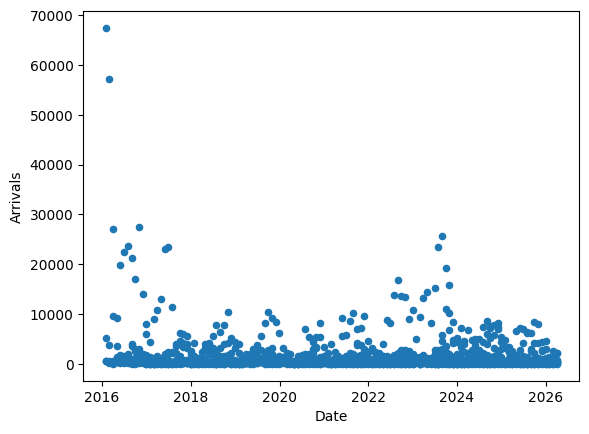

In [54]:
im1.plot(kind='scatter', x='Date', y='Arrivals');

In [68]:
im1['ISO3 - Country of arrival'].unique()

array(['BGR', 'CYP', 'ESP', 'GRC', 'ITA', 'MLT'], dtype=object)

In [71]:
im1[im1['Year']>2020]

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
5,2021-01-31,2021,1,BGR,EMR,Land,239
6,2021-01-31,2021,1,BGR,EMR,Land,10
7,2022-01-31,2022,1,BGR,EMR,Land,844
8,2022-01-31,2022,1,BGR,EMR,Land,2
9,2023-01-31,2023,1,BGR,EMR,Land,631
...,...,...,...,...,...,...,...
1123,2021-12-31,2021,12,MLT,CMR,Sea,134
1124,2022-12-31,2022,12,MLT,CMR,Sea,3
1125,2023-12-31,2023,12,MLT,CMR,Sea,47
1126,2024-12-31,2024,12,MLT,CMR,Sea,83


In [38]:
im2 = pd.read_excel('/content/DTM Europe_Q2_2026_Dataset.xlsx', sheet_name= 'First_Arrival_Countries_Monthly')

In [39]:
im2.shape

(1157, 7)

In [41]:
im2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1157 entries, 0 to 1156
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1157 non-null   datetime64[ns]
 1   Year                       1157 non-null   int64         
 2   Month                      1157 non-null   int64         
 3   ISO3 - Country of arrival  1157 non-null   object        
 4   Route                      1157 non-null   object        
 5   Type of arrival            1157 non-null   object        
 6   Arrivals                   1157 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 63.4+ KB


In [42]:
im2.head()

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,BGR,EMR,Land,596
1,2017-01-31,2017,1,BGR,EMR,Land,48
2,2018-01-31,2018,1,BGR,EMR,Land,116
3,2019-01-31,2019,1,BGR,EMR,Land,80
4,2020-01-31,2020,1,BGR,EMR,Land,75


In [70]:
im2[im2['Year']>2020]

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
5,2021-01-31,2021,1,BGR,EMR,Land,239
6,2021-01-31,2021,1,BGR,EMR,Land,10
7,2022-01-31,2022,1,BGR,EMR,Land,844
8,2022-01-31,2022,1,BGR,EMR,Land,2
9,2023-01-31,2023,1,BGR,EMR,Land,631
...,...,...,...,...,...,...,...
1152,2021-12-31,2021,12,MLT,CMR,Sea,134
1153,2022-12-31,2022,12,MLT,CMR,Sea,3
1154,2023-12-31,2023,12,MLT,CMR,Sea,47
1155,2024-12-31,2024,12,MLT,CMR,Sea,83


In [ ]:
im[im['ISO3 - Country of arrival'] == 'MNE']

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals


In [ ]:
im['ISO3 - Country of arrival'].unique()

array(['BGR', 'CYP', 'ESP', 'GRC', 'ITA', 'MLT'], dtype=object)

In [ ]:
im = pd.read_excel('/content/DTM Europe_Q2_2026_Dataset.xlsx', sheet_name= 'Other_Countries_Areas_Monthly')

In [ ]:
im.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1092 non-null   datetime64[ns]
 1   Year                       1092 non-null   int64         
 2   Month                      1092 non-null   int64         
 3   ISO3 - Country of arrival  1092 non-null   object        
 4   Route                      1092 non-null   object        
 5   Type of arrival            1092 non-null   object        
 6   Arrivals                   1092 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 59.8+ KB


In [65]:
im['ISO3 - Country of arrival'].unique()

array(['BGR', 'CYP', 'ESP', 'GRC', 'ITA', 'MLT'], dtype=object)

In [64]:
im#[im['ISO3 - Country of arrival'] == 'MNE']

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,BGR,EMR,Land,596
1,2017-01-31,2017,1,BGR,EMR,Land,48
2,2018-01-31,2018,1,BGR,EMR,Land,116
3,2019-01-31,2019,1,BGR,EMR,Land,80
4,2020-01-31,2020,1,BGR,EMR,Land,75
...,...,...,...,...,...,...,...
1123,2021-12-31,2021,12,MLT,CMR,Sea,134
1124,2022-12-31,2022,12,MLT,CMR,Sea,3
1125,2023-12-31,2023,12,MLT,CMR,Sea,47
1126,2024-12-31,2024,12,MLT,CMR,Sea,83


In [81]:
ivica = pd.read_excel('/content/DTM Europe_Q2_2026_Dataset.xlsx')

In [82]:
sheet_names = list(ivica['Unnamed: 3'].dropna().loc[7:11])

In [83]:
sheet_names

['First_Arrival_Countries_Monthly',
 'Other_Countries_Areas_Monthly',
 'First_Arrival_Countries_CoO',
 'Other_Countries_Areas_CoO',
 'All_Migrant_Presence']

In [86]:
for i, sheet in enumerate(xls.sheet_names, start=1):
  globals()['im_%s'%str(i)] = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name=sheet)

In [84]:
xls = pd.ExcelFile('/content/DTM Europe_Q1_2026_Dataset.xlsx')
xls.sheet_names

['About',
 'Summary',
 'First_Arrival_Countries_Monthly',
 'Other_Countries_Areas_Monthly',
 'First_Arrival_Countries_CoO',
 'Others_Countries_CoO',
 'All_Migrant_Presence',
 'Sources',
 'ISO3']

In [138]:
im_4.set_index('Date', inplace=True)

KeyError: "None of ['Date'] are in the columns"

In [140]:
im_4.sort_index(inplace=True)

<Axes: xlabel='Date'>

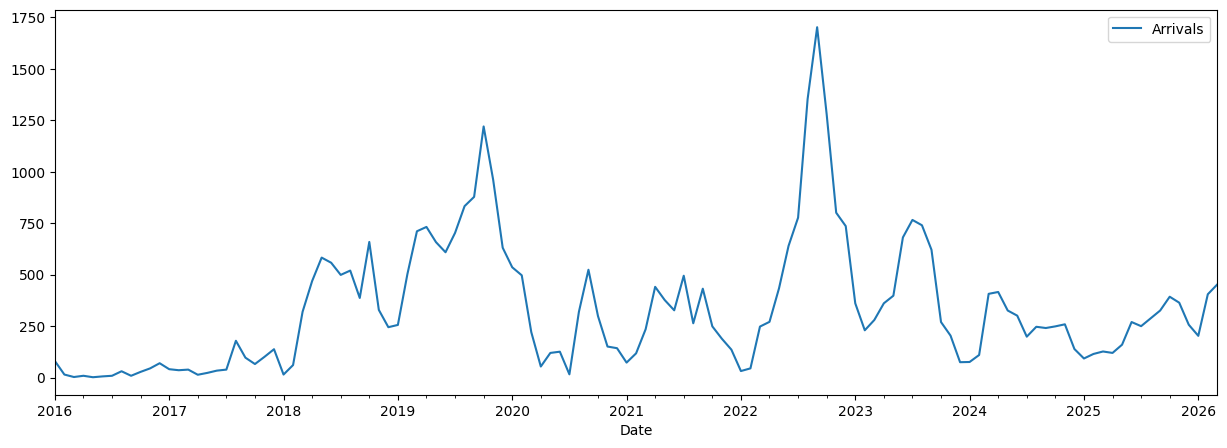

In [143]:
im_4[(im_4['ISO3 - Country of arrival']=='MNE')].plot(kind='line', y='Arrivals', figsize=(15,5))